In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

cuda


In [2]:
def show_images(images, nrow=3):
    images = images[:nrow*nrow].detach().cpu()
    print(images.shape)
    grid = make_grid(
        images,
        nrow=nrow,
        padding=2
    )
    plt.figure(figsize=(6,6))
    plt.imshow(grid.permute(1,2,0).squeeze(), cmap="gray")
    plt.axis("off")
    plt.show()

In [3]:
import pandas as pd
K = 4
class MNISTDataset(Dataset):
    def __init__(self, path, transform=None):
        super().__init__()
        df = pd.read_csv(path)
        self.labels = df['label'].to_numpy()
        self.len = len(df)
        self.data = df[df.columns[1:]].to_numpy().reshape(self.len, 28, 28)
        self.transform = transform
    def __len__(self):
        return self.len
    def __getitem__(self, index):
        img = self.data[index].astype(np.uint8)
        # print(img)
        if self.transform:
            img = self.transform(img)
        label = self.labels[index]
        return img, label

In [4]:
def binarize(x, threshold=0.5):
    return (x > threshold).long()

torch.Size([64, 1, 16, 16])
torch.Size([64, 1, 16, 16])
0 3
torch.Size([9, 1, 16, 16])


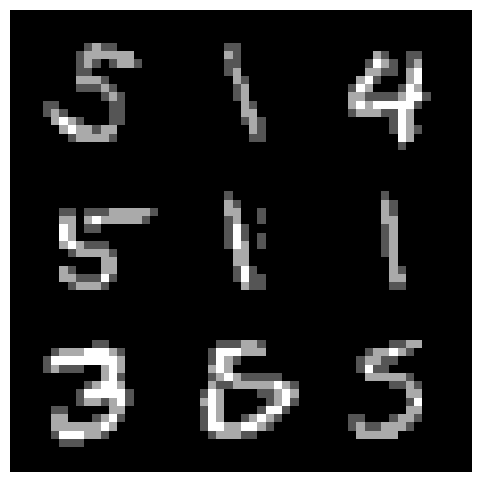

In [5]:
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((16, 16)),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: torch.round(x * (K - 1)).long())

])
train_dataset = MNISTDataset("mnist_train.csv", transform=transform)
len_train = int(len(train_dataset) * 0.9)
len_val = len(train_dataset) - len_train
train_dataset, val_dataset = torch.utils.data.random_split(dataset=train_dataset, lengths=[len_train, len_val])
test_dataset = MNISTDataset("mnist_test.csv", transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
images, _ = next(iter(train_loader))
targets = binarize(images)
print(images.shape)
print(targets.shape)
print(images.min().item(), images.max().item())
show_images(images.float()/(K-1))

In [6]:
images.min()

tensor(0)

In [7]:
images.max()

tensor(3)

In [8]:
class MaskedConv2d(nn.Conv2d):
    def __init__(self, mask_type, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.register_buffer("mask", torch.ones_like(self.weight))
        _, _, height, width = self.weight.shape
        kh, kw = height // 2, width // 2
        self.mask[:, :, kh + 1:, :] = 0
        if mask_type == "A":
            self.mask[:, :, kh, kw:] = 0
        else:
            self.mask[:, :, kh, kw+1:] = 0
    def forward(self, x):
        return F.conv2d(x, self.weight * self.mask, self.bias, self.stride, self.padding, self.dilation, self.groups)

In [9]:
class PixelCNN(nn.Module):
    def __init__(self, in_channels = 1, hidden_channels = 64, num_classes = K):
        super().__init__()
        layers = [
            MaskedConv2d("A", in_channels, hidden_channels, kernel_size=7, padding=3),
            nn.ReLU()
        ]
        for _ in range(5):
            layers.extend([
                MaskedConv2d("B", hidden_channels, hidden_channels, kernel_size=3, padding=1),
                nn.ReLU()
            ])
        layers.append(nn.Conv2d(hidden_channels, num_classes, kernel_size=1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

In [10]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    for images, _ in loader:
        images = images.to(device)
        inputs = images.float() / (K - 1)
        targets = images.squeeze(1).long()
        logits = model(inputs)
        loss = criterion(logits, targets)
        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size
    return total_loss / total_samples

In [11]:
def train_model(model, model_name, train_loader, val_loader, epochs=10, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses = []
    val_losses = []
    for epoch in range(epochs):
        model.train()
        current_train_loss = 0
        total_samples = 0
        for batch_idx, (images, _) in enumerate(train_loader):
            images = images.to(device)
            inputs = images.float() / (K - 1)
            # print(inputs.shape)
            targets = images.squeeze(1).long()
            optimizer.zero_grad()
            logits = model(inputs)
            # print(logits.shape)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            batch_size = images.size(0)
            current_train_loss += loss.item() * batch_size
            total_samples += batch_size
        avg_train_loss = current_train_loss / total_samples
        train_losses.append(avg_train_loss)
        avg_val_loss = evaluate(model, val_loader, criterion, device)
        val_losses.append(avg_val_loss)
        print(f'Epoch [{epoch+1}/{epochs}], {model_name} Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}')
        # print(f'Epoch [{epoch+1}/{epochs}], {model_name} Train Loss: {avg_train_loss:.4f}')
    # Plotting training and validation losses
    plt.figure(figsize=(10, 6))
    plt.plot(train_losses, label='Training Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.title(f'{model_name} Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

Epoch [1/10], pixelCNN Train Loss: 0.3304, Val Loss: 0.2593
Epoch [2/10], pixelCNN Train Loss: 0.2550, Val Loss: 0.2547
Epoch [3/10], pixelCNN Train Loss: 0.2484, Val Loss: 0.2447
Epoch [4/10], pixelCNN Train Loss: 0.2445, Val Loss: 0.2436
Epoch [5/10], pixelCNN Train Loss: 0.2417, Val Loss: 0.2396
Epoch [6/10], pixelCNN Train Loss: 0.2395, Val Loss: 0.2381
Epoch [7/10], pixelCNN Train Loss: 0.2374, Val Loss: 0.2366
Epoch [8/10], pixelCNN Train Loss: 0.2354, Val Loss: 0.2350
Epoch [9/10], pixelCNN Train Loss: 0.2337, Val Loss: 0.2327
Epoch [10/10], pixelCNN Train Loss: 0.2320, Val Loss: 0.2321


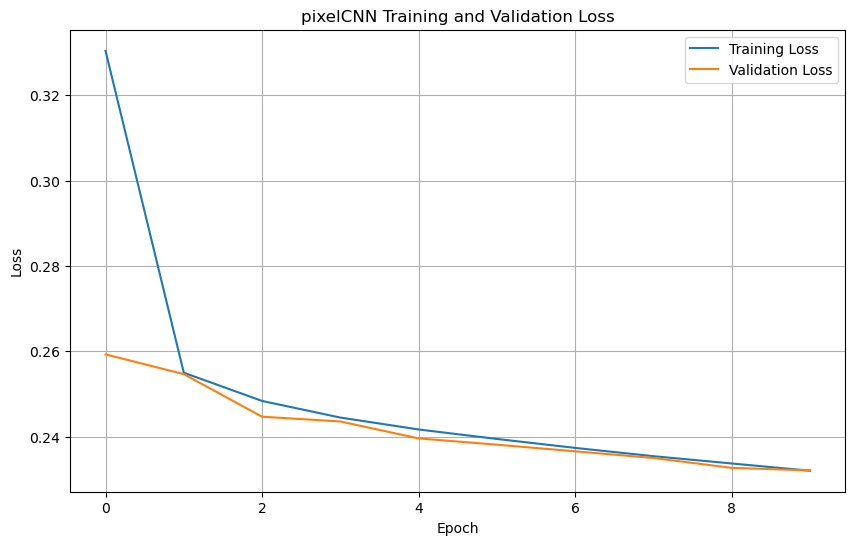

In [12]:
model = PixelCNN()
train_model(model, "pixelCNN", train_loader, val_loader)

In [13]:
import math
test_loss = evaluate(model, test_loader, nn.CrossEntropyLoss(), device)
bpd = test_loss / math.log(2)
print(bpd)

0.3326596217611428


In [14]:
@torch.no_grad()
def generate_samples(model, num_samples = 16, height=16, width=16, device="cpu"):
    model.eval()
    samples = torch.zeros(num_samples, 1, height, width, device=device)
    for row in range(height):
        for col in range(width):
            logits = model(samples.float() / (K - 1))
            pixel_logits = logits[:, :, row, col]
            probabilities = torch.softmax(pixel_logits, dim=1)
            sampled_pixel = torch.multinomial(probabilities, num_samples=1).squeeze(1)
            samples[:, 0, row, col] = sampled_pixel
    return samples

torch.Size([9, 1, 16, 16])


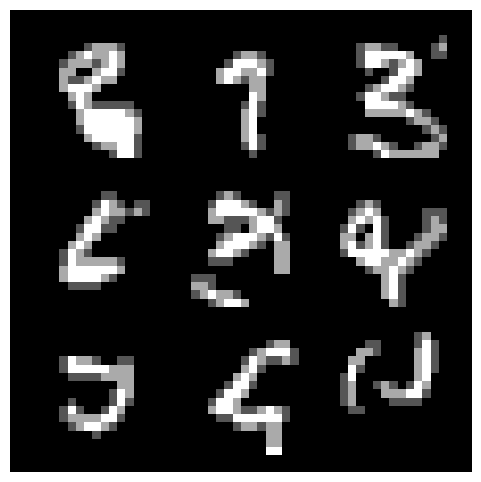

In [15]:
samples = generate_samples(model, device=device)
show_images(samples.float() / (K-1))

In [16]:
class PixelRNN(nn.Module):
    def __init__(
        self,
        num_classes=K
    ):
        super().__init__()
        self.tok_emb = nn.Embedding(5, 16)
        self.lstm = nn.LSTM(16, 64, batch_first=True)
        self.output_head = nn.Linear(64, num_classes)
    def forward(self, images, hidden=None):
        target_tokens = images.flatten(start_dim=1).long()
        input_tokens = torch.full_like(target_tokens, 4)
        input_tokens[:, 1:] = target_tokens[:, :-1]
        emb = self.tok_emb(input_tokens)
        out, hidden = self.lstm(emb, hidden)
        logits = self.output_head(out)
        return logits, target_tokens

In [17]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    for images, _ in loader:
        images = images.to(device)
        logits, targets = model(images)
        loss = F.cross_entropy(logits.reshape(-1, K), targets.reshape(-1))
        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size
    return total_loss / total_samples

def train_model(model, model_name, train_loader, val_loader, epochs=10, lr=0.001):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses = []
    val_losses = []
    for epoch in range(epochs):
        model.train()
        current_train_loss = 0
        total_samples = 0
        for batch_idx, (images, _) in enumerate(train_loader):
            images = images.to(device)
            optimizer.zero_grad()
            logits, targets = model(images)
            # print(logits.shape)
            loss = F.cross_entropy(logits.reshape(-1, K), targets.reshape(-1))
            loss.backward()
            optimizer.step()
            batch_size = images.size(0)
            current_train_loss += loss.item() * batch_size
            total_samples += batch_size
        avg_train_loss = current_train_loss / total_samples
        train_losses.append(avg_train_loss)
        avg_val_loss = evaluate(model, val_loader, device)
        val_losses.append(avg_val_loss)
        print(f'Epoch [{epoch+1}/{epochs}], {model_name} Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}')
        # print(f'Epoch [{epoch+1}/{epochs}], {model_name} Train Loss: {avg_train_loss:.4f}')
    # Plotting training and validation losses
    plt.figure(figsize=(10, 6))
    plt.plot(train_losses, label='Training Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.title(f'{model_name} Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

Epoch [1/10], pixelRNN Train Loss: 0.4125, Val Loss: 0.3061
Epoch [2/10], pixelRNN Train Loss: 0.2900, Val Loss: 0.2817
Epoch [3/10], pixelRNN Train Loss: 0.2728, Val Loss: 0.2642
Epoch [4/10], pixelRNN Train Loss: 0.2592, Val Loss: 0.2555
Epoch [5/10], pixelRNN Train Loss: 0.2508, Val Loss: 0.2484
Epoch [6/10], pixelRNN Train Loss: 0.2453, Val Loss: 0.2460
Epoch [7/10], pixelRNN Train Loss: 0.2414, Val Loss: 0.2406
Epoch [8/10], pixelRNN Train Loss: 0.2383, Val Loss: 0.2379
Epoch [9/10], pixelRNN Train Loss: 0.2360, Val Loss: 0.2345
Epoch [10/10], pixelRNN Train Loss: 0.2340, Val Loss: 0.2331


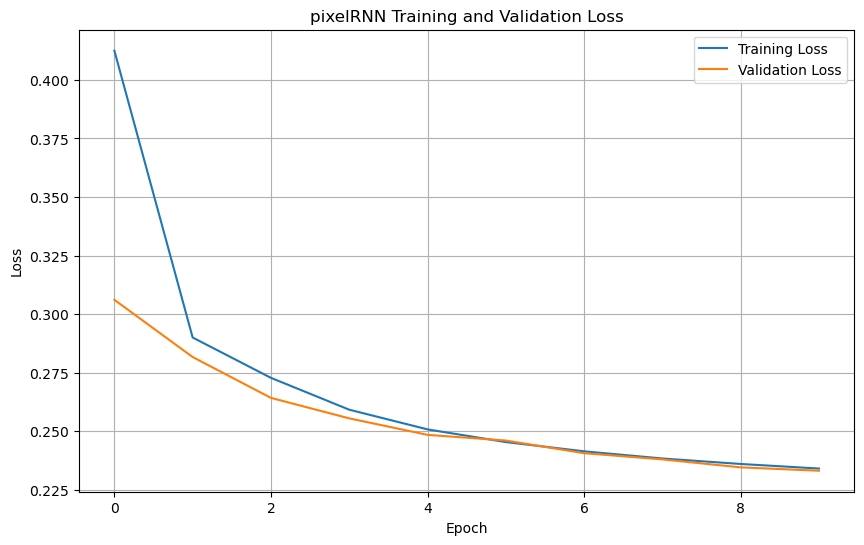

In [18]:
model_p = PixelRNN()
train_model(model_p, "pixelRNN", train_loader, val_loader)

In [19]:
test_loss = evaluate(model_p, test_loader, device)
bpd = test_loss / math.log(2)
print(bpd)

0.33431748605074924


In [20]:
@torch.no_grad()
def generate(model, num_samples=25, height=16, width=16, device="cpu"):
    model.eval()
    sequence = torch.zeros(num_samples, height * width, dtype=torch.long, device=device)
    input_token = torch.full((num_samples, 1), 4, dtype=torch.long, device=device)
    hidden = None
    for t in range(height * width):
        emb = model.tok_emb(input_token)
        out, hidden = model.lstm(emb, hidden)
        logits = model.output_head(out[:, -1, :])
        probabilities = torch.softmax(logits, dim=1)
        sampled_pixel = torch.multinomial(probabilities, num_samples=1)
        sequence[:, t] = sampled_pixel.squeeze(1)
        input_token = sampled_pixel
    return sequence.view(num_samples, 1, height, width)

torch.Size([9, 1, 16, 16])


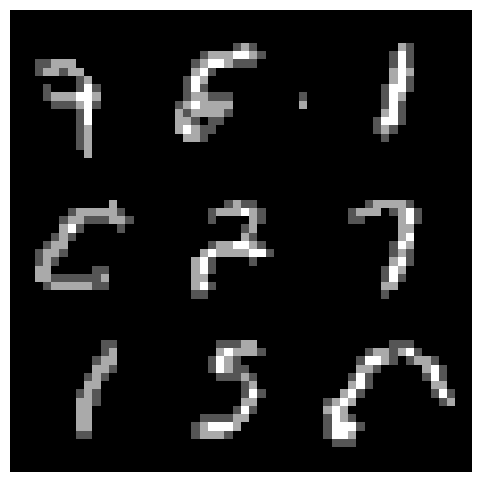

In [21]:
samples = generate(model_p, device=device)
show_images(samples.float() / (K-1))

| Model | BPD | Training time |
| --- | --- | --- |
| PixelCNN | 0.33266 | 239s |
| PixelRNN | 0.33432 | 231s |